In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from src import true_func, generate_data, MLPRegression

X, y = generate_data(n_sample=75, noise_std=0.12, seed=42)


Text(0, 0.5, 'f*(X)')

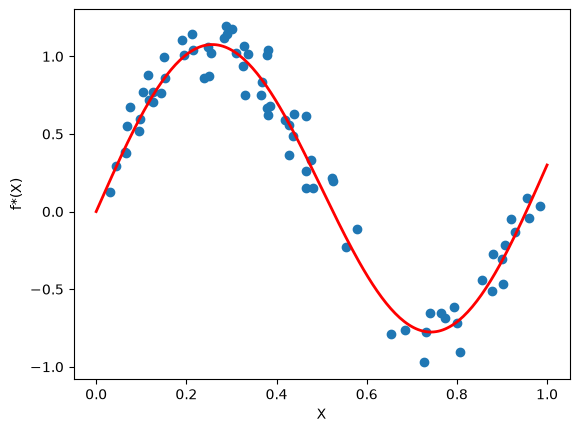

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

x = np.linspace(start=0, stop=1, num=200).reshape(-1, 1)

fig, axes = plt.subplots(1, 1)

axes.scatter(x=X, y=y)
axes.plot(x, true_func(x), c='r', linewidth=2)

axes.set_xlabel('X')
axes.set_ylabel('f*(X)')

In [ ]:
# MLPRegression is defined once in src.py and imported in Cell 0.


In [4]:
model = MLPRegression(hid_dim=32)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss='mse'
    )

history = model.fit(
    X,
    y,
    epochs=2000,
    verbose=0
)

print(f"Final training MSE: {history.history['loss'][-1]:.3f}")


Final training MSE: 0.015


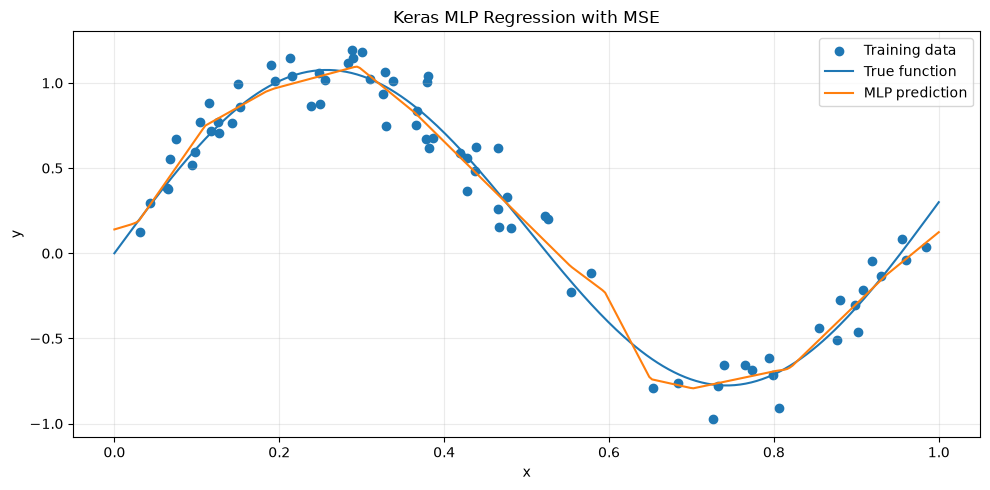

In [5]:

x_grid = np.linspace(0, 1, 300).reshape(-1, 1)
y_true = true_func(x_grid)

y_pred = model.predict(x_grid, verbose=0)

plt.figure(figsize=(10, 5))

plt.scatter(X[:, 0], y[:, 0], label="Training data")
plt.plot(x_grid[:, 0], y_true[:, 0], label="True function")
plt.plot(x_grid[:, 0], y_pred[:, 0], label="MLP prediction")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Keras MLP Regression with MSE")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


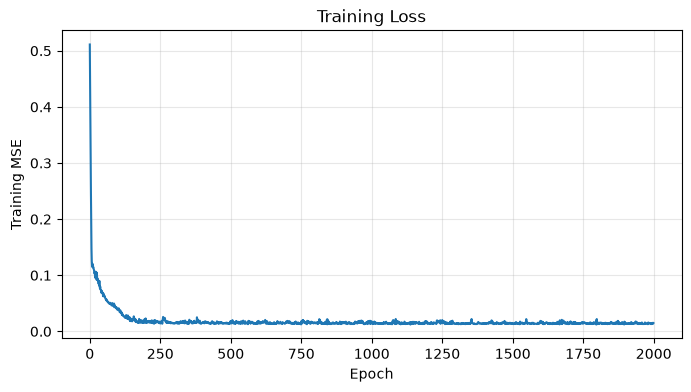

In [6]:

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
sigma = 0.2
sigma2 = sigma**2


def gaussian_nll(y_true, y_pred):
    constant = 0.5 * tf.math.log(
        2.0 * np.pi * sigma2
    )

    squared_error = tf.square(y_true - y_pred)

    return tf.reduce_mean(
        constant + squared_error / (2.0 * sigma2)
    )


# Build a fresh model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_mle = MLPRegression(hid_dim=64)

model_mle.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=gaussian_nll
)

history_mle = model_mle.fit(
    X,
    y,
    epochs=1000,
    verbose=0
)

# Report both metrics
y_pred_train = model_mle.predict(X, verbose=0)

mse = np.mean((y - y_pred_train)**2)
nll = history_mle.history["loss"][-1]

print(f"Training MSE: {mse:.6f}")
print(f"Training Gaussian NLL: {nll:.6f}")



Training MSE: 0.014154
Training Gaussian NLL: -0.509955


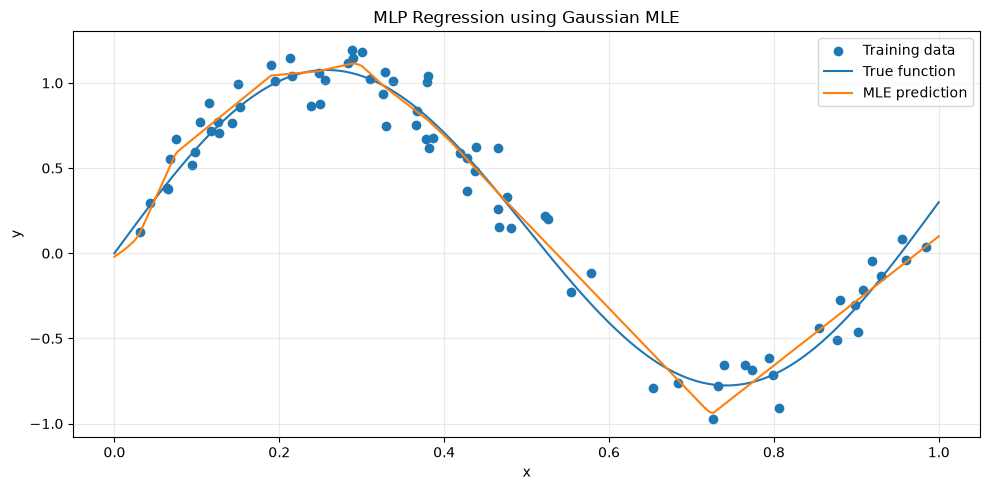

In [9]:

x_grid = np.linspace(0, 1, 300).reshape(-1, 1)

y_true = true_func(x_grid)
y_pred = model_mle.predict(x_grid, verbose=0)

plt.figure(figsize=(10, 5))
plt.scatter(X[:, 0], y[:, 0], label="Training data")
plt.plot(x_grid[:, 0], y_true[:, 0], label="True function")
plt.plot(x_grid[:, 0], y_pred[:, 0], label="MLE prediction")

plt.xlabel("x")
plt.ylabel("y")
plt.title("MLP Regression using Gaussian MLE")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [10]:
# The shared MLPRegression class (including optional L2 regularization)
# is imported from src.py in Cell 0. No duplicate definition is needed.


In [11]:
n = len(X)
sigma = 0.2
sigma2 = sigma**2

# Gaussian prior on the regularized network kernels: w ~ N(0, tau^2)
tau = 1.0

# Mean Gaussian NLL + lambda * sum(kernel^2) matches the average
# negative log-posterior when lambda = 1 / (2 * n * tau^2).
l2_lambda = 1.0 / (2.0 * n * tau**2)


def gaussian_nll(y_true, y_pred):
    constant = 0.5 * tf.math.log(2.0 * np.pi * sigma2)
    squared_error = tf.square(y_true - y_pred)
    return tf.reduce_mean(constant + squared_error / (2.0 * sigma2))


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_map = MLPRegression(hid_dim=64, l2_lambda=l2_lambda)
model_map.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=gaussian_nll
)
history_map = model_map.fit(X, y, epochs=1000, verbose=0)

y_pred_map = model_map.predict(X, verbose=0)
mse_map = np.mean((y - y_pred_map)**2)

print(f"L2 coefficient: {l2_lambda:.6f}")
print(f"MAP training MSE: {mse_map:.6f}")
print(f"MAP training Gaussian NLL (data-fit only): {gaussian_nll(y, y_pred_map).numpy():.6f}")
print(f"MAP total objective: {model_map.evaluate(X, y, verbose=0):.6f}")


L2 coefficient: 0.006667
MAP training MSE: 0.015314
MAP training NLL: -0.310858
MAP total objective: -0.313422


In [12]:
y_pred_map = model_map.predict(X, verbose=0)

# Keras evaluate() includes model.losses, i.e. the L2 penalty.
data_nll = gaussian_nll(y, y_pred_map).numpy()
regularization = float(tf.add_n(model_map.losses).numpy()) if model_map.losses else 0.0
total_objective = float(model_map.evaluate(X, y, verbose=0))

print("Number of samples:", len(X))
print("tau:", tau)
print("L2 coefficient:", l2_lambda)
print(f"MAP training MSE: {np.mean((y - y_pred_map)**2):.6f}")
print(f"Data-fit Gaussian NLL: {data_nll:.6f}")
print(f"Regularization penalty: {regularization:.6f}")
print(f"Total objective (data NLL + penalty): {total_objective:.6f}")


Number of samples: 75
tau: 1.0
L2 coefficient: 0.006666666666666667
MAP training MSE: 0.015314
MAP training NLL: -0.499076
Regularization penalty: 0.185653
MAP total objective: -0.313422


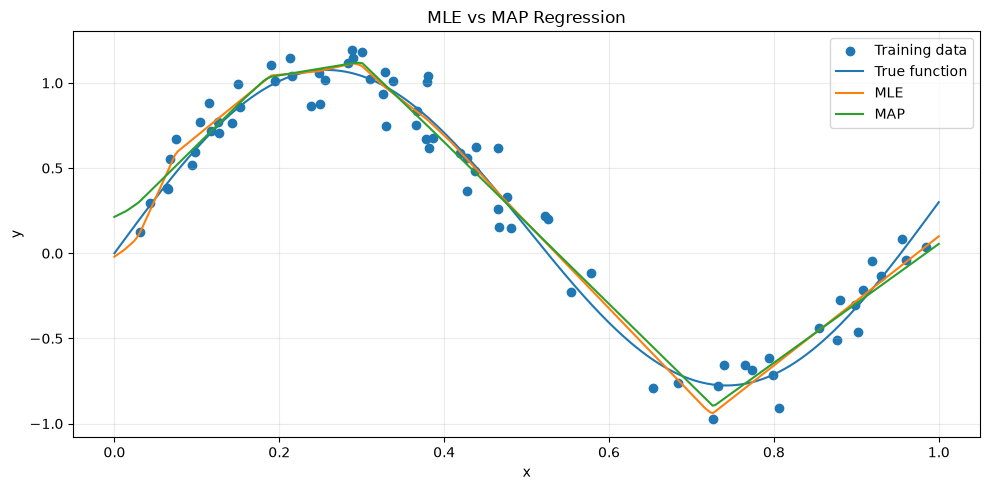

In [13]:

x_grid = np.linspace(0, 1, 300).reshape(-1, 1)
y_true = true_func(x_grid)

y_pred_mle = model_mle.predict(x_grid, verbose=0)
y_pred_map = model_map.predict(x_grid, verbose=0)

plt.figure(figsize=(10, 5))

plt.scatter(X[:, 0], y[:, 0], label="Training data")
plt.plot(x_grid[:, 0], y_true[:, 0], label="True function")
plt.plot(x_grid[:, 0], y_pred_mle[:, 0], label="MLE")
plt.plot(x_grid[:, 0], y_pred_map[:, 0], label="MAP")

plt.xlabel("x")
plt.ylabel("y")
plt.title("MLE vs MAP Regression")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [14]:
X_train, y_train = generate_data(
    n_sample=75,
    noise_std=0.2,
    seed=42
)

# Test data: different random samples
X_test, y_test = generate_data(
    n_sample=500,
    noise_std=0.2,
    seed=123
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 75
Test samples: 500


In [15]:
n = len(X_train)

sigma = 0.2
sigma2 = sigma**2
tau = 1.0

# Exact coefficient for mean Gaussian NLL + L2 kernel penalty.
l2_lambda = 1.0 / (2.0 * n * tau**2)

def gaussian_nll(y_true, y_pred):
    constant = 0.5 * np.log(2.0 * np.pi * sigma2)
    squared_error = tf.square(y_true - y_pred)

    return tf.reduce_mean(
        constant + squared_error / (2.0 * sigma2)
    )


# ---------------- MLE ----------------

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_mle = MLPRegression(
    hid_dim=64,
    l2_lambda=0.0
)

model_mle.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=gaussian_nll
)

history_mle = model_mle.fit(
    X_train,
    y_train,
    epochs=1000,
    verbose=0
)


# ---------------- MAP ----------------

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_map = MLPRegression(
    hid_dim=64,
    l2_lambda=l2_lambda
)

model_map.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=gaussian_nll
)

history_map = model_map.fit(
    X_train,
    y_train,
    epochs=1000,
    verbose=0
)

print(f"L2 coefficient: {l2_lambda:.6f}")

L2 coefficient: 0.006667


In [16]:
pred_mle = model_mle.predict(X_test, verbose=0)
pred_map = model_map.predict(X_test, verbose=0)

train_mse_mle = np.mean(
    (y_train - model_mle.predict(X_train, verbose=0))**2
)
train_mse_map = np.mean(
    (y_train - model_map.predict(X_train, verbose=0))**2
)

test_mse_mle = np.mean((y_test - pred_mle)**2)
test_mse_map = np.mean((y_test - pred_map)**2)

print(f"MLE train MSE: {train_mse_mle:.6f}")
print(f"MAP train MSE: {train_mse_map:.6f}")
print(f"MLE test MSE:  {test_mse_mle:.6f}")
print(f"MAP test MSE:  {test_mse_map:.6f}")

MLE train MSE: 0.024898
MAP train MSE: 0.025946
MLE test MSE:  0.047455
MAP test MSE:  0.048868


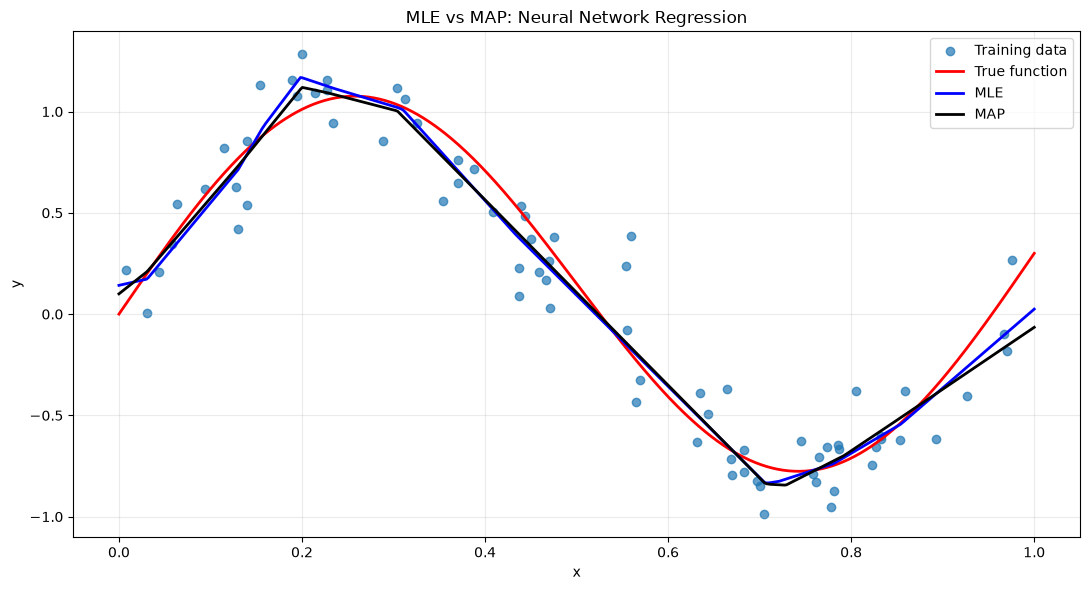

In [17]:
x_grid = np.linspace(0, 1, 500).reshape(-1, 1)

y_true = np.sin(2 * np.pi * x_grid) + 0.3 * x_grid
y_mle = model_mle.predict(x_grid, verbose=0)
y_map = model_map.predict(x_grid, verbose=0)

plt.figure(figsize=(11, 6))

plt.scatter(
    X_train[:, 0], y_train[:, 0],
    label="Training data", alpha=0.7
)

plt.plot(
    x_grid[:, 0], y_true[:, 0],
    label="True function", linewidth=2,
    c='red'
)

plt.plot(
    x_grid[:, 0], y_mle[:, 0],
    label="MLE", linewidth=2,
    c='b'
)

plt.plot(
    x_grid[:, 0], y_map[:, 0],
    label="MAP", linewidth=2,
    c='black'
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("MLE vs MAP: Neural Network Regression")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [21]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Experiment settings
sample_sizes = [15, 30, 50, 75]
n_repeats = 5
epochs = 500

noise_std = 0.2
tau = 1.0
hid_dim = 64

# A fixed test set for fair comparison
X_test, y_test = generate_data(
    n_sample=500,
    noise_std=noise_std,
    seed=999
)

# Store test MSE for each repetition and sample size
mse_mle = np.zeros((n_repeats, len(sample_sizes)))
mse_map = np.zeros((n_repeats, len(sample_sizes)))

for i, n_train in enumerate(sample_sizes):

    for r in range(n_repeats):

        # Generate training data
        data_seed = 10_000 + i * 100 + r

        X_train, y_train = generate_data(
            n_sample=n_train,
            noise_std=noise_std,
            seed=data_seed
        )

        # -------------------------
        # 1. MLE
        # -------------------------
        tf.keras.backend.clear_session()

        init_seed = 2_000 + i * 100 + r
        tf.keras.utils.set_random_seed(init_seed)

        model_mle = MLPRegression(
            hid_dim=hid_dim,
            l2_lambda=0.0
        )

        model_mle.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="mse"
        )

        model_mle.fit(
            X_train,
            y_train,
            epochs=epochs,
            verbose=0
        )

        y_pred_mle = model_mle.predict(
            X_test, verbose=0
        )

        mse_mle[r, i] = np.mean(
            (y_test - y_pred_mle) ** 2
        )

        # -------------------------
        # 2. MAP
        # -------------------------
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(init_seed)

        # With MSE data loss, scale the Gaussian MAP penalty accordingly:
        # MSE + (sigma^2 / (n * tau^2)) * sum(kernel^2).
        l2_lambda = noise_std**2 / (n_train * tau**2)

        model_map = MLPRegression(
            hid_dim=hid_dim,
            l2_lambda=l2_lambda
        )

        model_map.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="mse"
        )

        model_map.fit(
            X_train,
            y_train,
            epochs=epochs,
            verbose=0
        )

        y_pred_map = model_map.predict(
            X_test, verbose=0
        )

        mse_map[r, i] = np.mean(
            (y_test - y_pred_map) ** 2
        )

    print(f"Finished: n_train = {n_train}")

print("Experiment completed!")

Finished: n_train = 15
Finished: n_train = 30
Finished: n_train = 50
Finished: n_train = 75
Experiment completed!


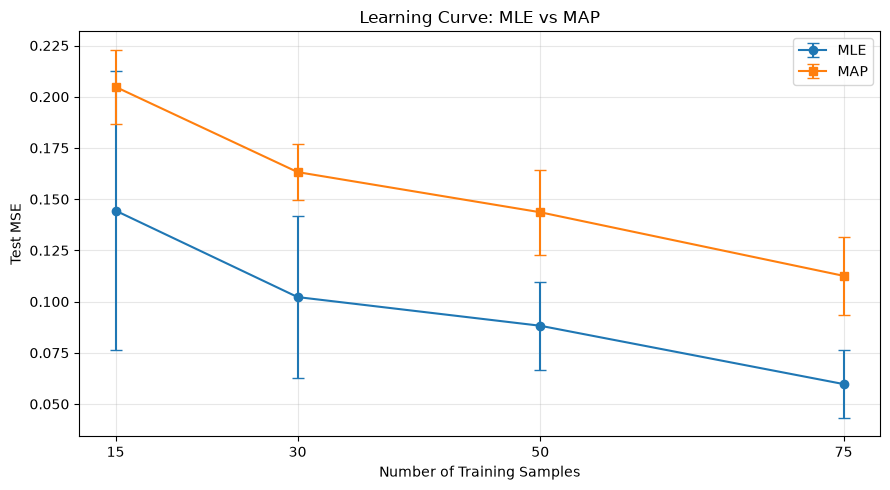

In [22]:
mean_mle = mse_mle.mean(axis=0)
std_mle = mse_mle.std(axis=0)

mean_map = mse_map.mean(axis=0)
std_map = mse_map.std(axis=0)

plt.figure(figsize=(9, 5))

plt.errorbar(
    sample_sizes,
    mean_mle,
    yerr=std_mle,
    marker="o",
    capsize=4,
    label="MLE"
)

plt.errorbar(
    sample_sizes,
    mean_map,
    yerr=std_map,
    marker="s",
    capsize=4,
    label="MAP"
)

plt.xlabel("Number of Training Samples")
plt.ylabel("Test MSE")
plt.title("Learning Curve: MLE vs MAP")

plt.xticks(sample_sizes)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
print(
    f"{'Samples':>8} | "
    f"{'MLE Test MSE':>18} | "
    f"{'MAP Test MSE':>18}"
)

print("-" * 52)

for i, n in enumerate(sample_sizes):
    print(
        f"{n:8d} | "
        f"{mean_mle[i]:.4f} ± {std_mle[i]:.4f} | "
        f"{mean_map[i]:.4f} ± {std_map[i]:.4f}"
    )

 Samples |       MLE Test MSE |       MAP Test MSE
----------------------------------------------------
      15 | 0.1444 ± 0.0683 | 0.2048 ± 0.0181
      30 | 0.1022 ± 0.0395 | 0.1632 ± 0.0135
      50 | 0.0882 ± 0.0215 | 0.1436 ± 0.0208
      75 | 0.0597 ± 0.0166 | 0.1126 ± 0.0189


In [25]:

# Fixed dataset
n_train = 75
noise_std = 0.2
tau = 1.0

X_train, y_train = generate_data(
    n_sample=n_train,
    noise_std=noise_std,
    seed=123
)

X_test, y_test = generate_data(
    n_sample=500,
    noise_std=noise_std,
    seed=999
)

# Regularization coefficients
lambdas = [
    0.0,
    0.0001,
    0.001,
    noise_std**2 / (n_train * tau**2),
    0.01,
    0.03
]

epochs = 500
test_mse = []
train_mse = []

for lam in lambdas:

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(2026)

    model = MLPRegression(
        hid_dim=64,
        l2_lambda=lam
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    model.fit(
        X_train,
        y_train,
        epochs=epochs,
        verbose=0
    )

    # Predictions
    y_train_pred = model.predict(X_train, verbose=0)
    y_test_pred = model.predict(X_test, verbose=0)

    # Data-fit MSE (without regularization penalty)
    train_mse.append(
        np.mean((y_train - y_train_pred) ** 2)
    )

    test_mse.append(
        np.mean((y_test - y_test_pred) ** 2)
    )

    print(f"lambda = {lam:.5f} | "
          f"Train MSE = {train_mse[-1]:.5f} | "
          f"Test MSE = {test_mse[-1]:.5f}")

lambda = 0.00000 | Train MSE = 0.03539 | Test MSE = 0.06768
lambda = 0.00010 | Train MSE = 0.03807 | Test MSE = 0.07338
lambda = 0.00100 | Train MSE = 0.04216 | Test MSE = 0.07979
lambda = 0.00667 | Train MSE = 0.09043 | Test MSE = 0.12172
lambda = 0.01000 | Train MSE = 0.11079 | Test MSE = 0.14074
lambda = 0.03000 | Train MSE = 0.13866 | Test MSE = 0.17197


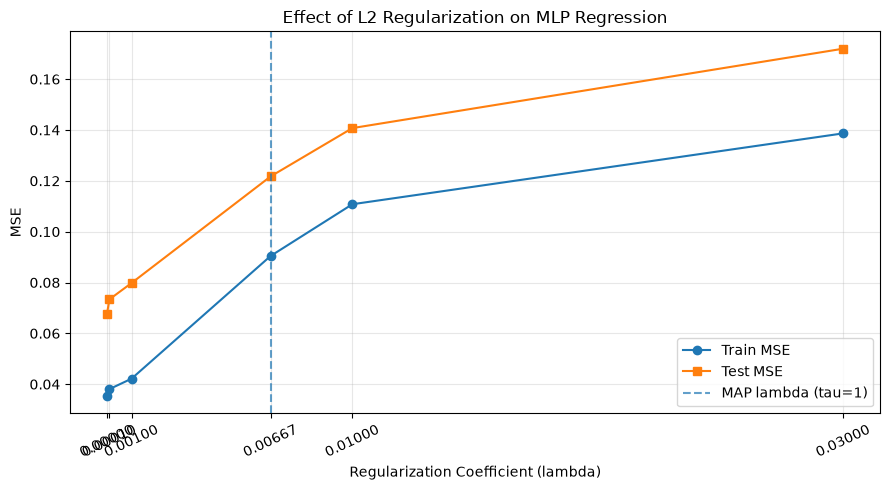

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    lambdas,
    train_mse,
    marker="o",
    label="Train MSE"
)

plt.plot(
    lambdas,
    test_mse,
    marker="s",
    label="Test MSE"
)

plt.axvline(
    noise_std**2 / (n_train * tau**2),
    linestyle="--",
    alpha=0.7,
    label="Scaled MAP lambda (tau=1)"
)

plt.xlabel("Regularization Coefficient (lambda)")
plt.ylabel("MSE")
plt.title("Effect of L2 Regularization on MLP Regression")
plt.xticks(lambdas, [f"{x:.5f}" for x in lambdas],
           rotation=25)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:


# Fixed dataset
X_train, y_train = generate_data(
    n_sample=75,
    noise_std=0.2,
    seed=123
)

epochs = 500
tau = 1.0
n_train = len(X_train)

noise_std = 0.2
lambda_map = noise_std**2 / (n_train * tau**2)

def train_and_record(l2_lambda):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(2026)

    model = MLPRegression(
        hid_dim=64,
        l2_lambda=l2_lambda
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        verbose=0
    )

    # Keras history records the optimized objective: MSE for MLE, and
    # MSE + L2 penalty for MAP. The MAP coefficient is scaled for MSE.
    return history.history["loss"]

mse_mle = train_and_record(l2_lambda=0.0)
mse_map = train_and_record(l2_lambda=lambda_map)

print("Training completed.")

Training completed.


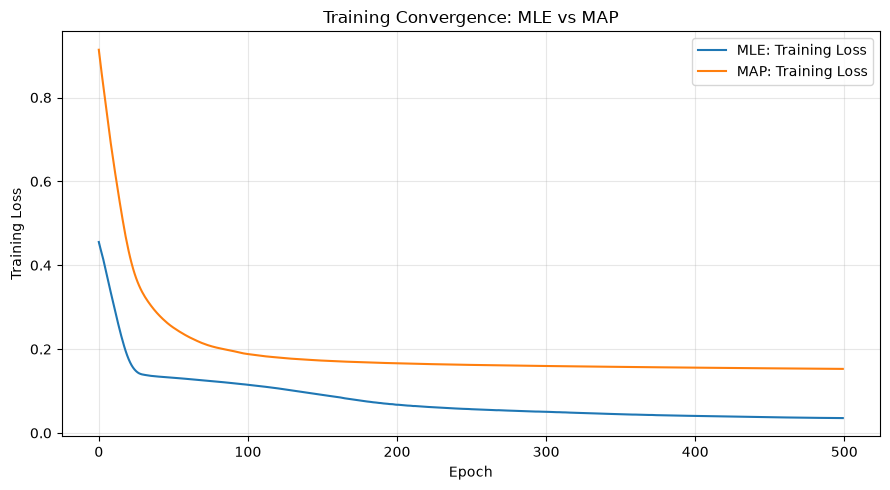

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
    mse_mle,
    label="MLE: MSE objective"
)

plt.plot(
    mse_map,
    label="MAP: MSE + L2 objective"
)

plt.xlabel("Epoch")
plt.ylabel("Optimized Objective")
plt.title("Training Convergence: MLE vs MAP Objective")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

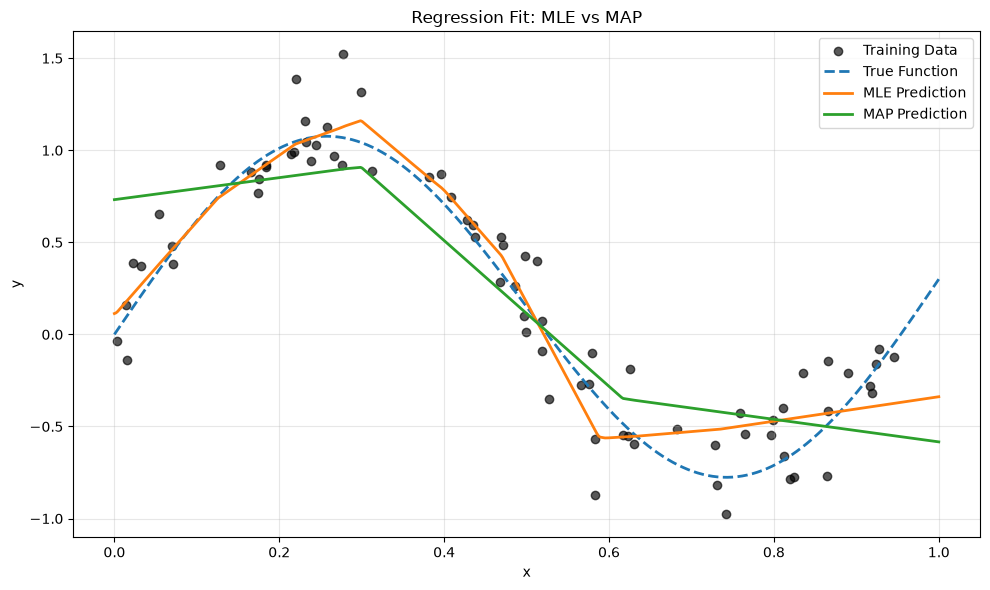

In [30]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Fixed training data
X_train, y_train = generate_data(
    n_sample=75,
    noise_std=0.2,
    seed=123
)

n_train = len(X_train)
tau = 1.0
noise_std = 0.2
lambda_map = noise_std**2 / (n_train * tau**2)

def fit_model(l2_lambda):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(2026)

    model = MLPRegression(
        hid_dim=64,
        l2_lambda=l2_lambda
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse"
    )

    model.fit(
        X_train, y_train,
        epochs=500,
        verbose=0
    )

    return model

model_mle = fit_model(0.0)
model_map = fit_model(lambda_map)

# Smooth grid for plotting
X_grid = np.linspace(0, 1, 500).reshape(-1, 1)

y_true = true_func(X_grid)
y_pred_mle = model_mle.predict(X_grid, verbose=0)
y_pred_map = model_map.predict(X_grid, verbose=0)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train.ravel(), y_train.ravel(),
    color="black", alpha=0.65,
    label="Training Data"
)

plt.plot(
    X_grid.ravel(), y_true.ravel(),
    linestyle="--", linewidth=2,
    label="True Function"
)

plt.plot(
    X_grid.ravel(), y_pred_mle.ravel(),
    linewidth=2, label="MLE Prediction"
)

plt.plot(
    X_grid.ravel(), y_pred_map.ravel(),
    linewidth=2, label="MAP Prediction"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Regression Fit: MLE vs MAP")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

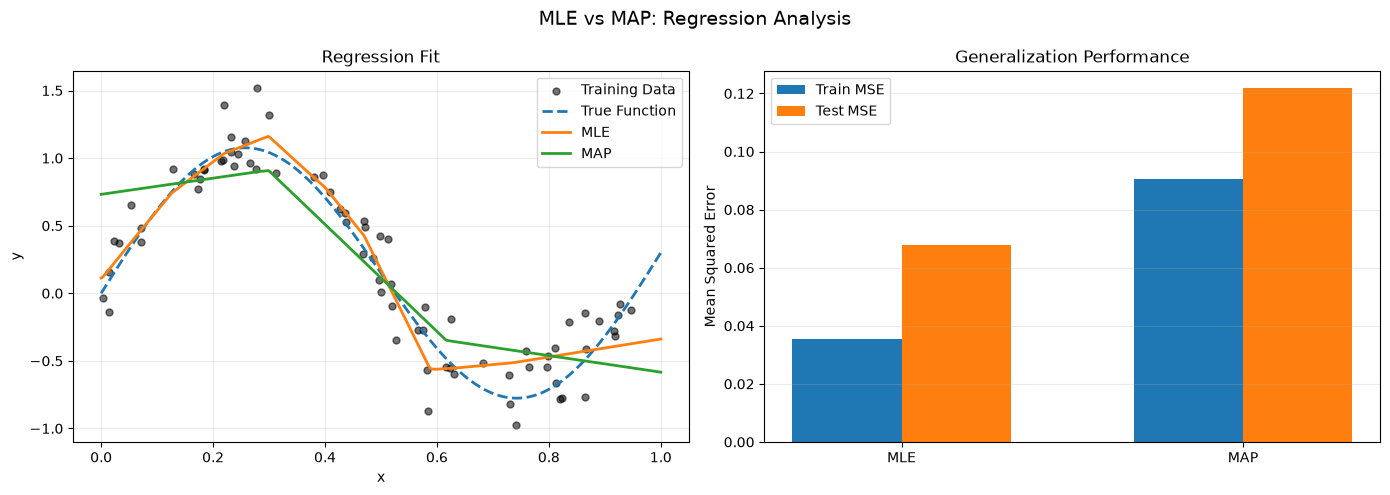

MLE Train MSE: 0.03539
MLE Test MSE:  0.06768
MAP Train MSE: 0.09043
MAP Test MSE:  0.12172


In [32]:
# Define the test set here so the final summary cell is self-contained.
X_test, y_test = generate_data(
    n_sample=500, noise_std=0.2, seed=999
)


# Predictions on training data
y_train_mle = model_mle.predict(X_train, verbose=0)
y_train_map = model_map.predict(X_train, verbose=0)

# Predictions on test data
y_test_mle = model_mle.predict(X_test, verbose=0)
y_test_map = model_map.predict(X_test, verbose=0)

# Calculate data-fit MSE
train_mse_mle = np.mean((y_train - y_train_mle) ** 2)
train_mse_map = np.mean((y_train - y_train_map) ** 2)

test_mse_mle = np.mean((y_test - y_test_mle) ** 2)
test_mse_map = np.mean((y_test - y_test_map) ** 2)

# Smooth prediction grid
X_grid = np.linspace(0, 1, 500).reshape(-1, 1)
y_true = true_func(X_grid)

y_grid_mle = model_mle.predict(X_grid, verbose=0)
y_grid_map = model_map.predict(X_grid, verbose=0)

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Regression fit
ax = axes[0]

ax.scatter(
    X_train.ravel(), y_train.ravel(),
    color="black", alpha=0.55, s=25,
    label="Training Data"
)

ax.plot(
    X_grid.ravel(), y_true.ravel(),
    "--", linewidth=2, label="True Function"
)

ax.plot(
    X_grid.ravel(), y_grid_mle.ravel(),
    linewidth=2, label="MLE"
)

ax.plot(
    X_grid.ravel(), y_grid_map.ravel(),
    linewidth=2, label="MAP"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Regression Fit")
ax.grid(alpha=0.25)
ax.legend()

# Panel 2: Train/Test MSE
ax = axes[1]

labels = ["MLE", "MAP"]
train_values = [train_mse_mle, train_mse_map]
test_values = [test_mse_mle, test_mse_map]

x = np.arange(len(labels))
width = 0.32

ax.bar(
    x - width / 2, train_values,
    width, label="Train MSE"
)

ax.bar(
    x + width / 2, test_values,
    width, label="Test MSE"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Mean Squared Error")
ax.set_title("Generalization Performance")
ax.grid(axis="y", alpha=0.25)
ax.legend()

fig.suptitle("MLE vs MAP: Regression Analysis", fontsize=14)
fig.tight_layout()
plt.show()

print(f"MLE Train MSE: {train_mse_mle:.5f}")
print(f"MLE Test MSE:  {test_mse_mle:.5f}")
print(f"MAP Train MSE: {train_mse_map:.5f}")
print(f"MAP Test MSE:  {test_mse_map:.5f}")